# Clasificación de reseñas hoteleras

**Proyectos de Machine Learning · CENESTUR**
**Integrantes:** Bryan Velastegui, Evelyn Morocho y Erika Gudiño

El problema consiste en clasificar el texto de una reseña como **negativa (0)** o **positiva (1)** para apoyar la revisión de comentarios de huéspedes. El cuaderno reproduce el flujo de la materia: adquirir datos reales, limpiarlos, separar conjuntos por grupos, entrenar, ajustar parámetros, medir el desempeño y guardar el pipeline que utiliza la API.

Se usa [Andalusian Hotels’ Reviews v3](https://www.kaggle.com/datasets/chizhikchi/andalusian-hotels-reviews-unbalanced/versions/3), publicado por Mariia Chizhikova en Kaggle con licencia declarada CC BY-NC 4.0. Las estrellas son una aproximación al sentimiento.

## 1. Entorno y parámetros

Ejecutar de arriba abajo desde la carpeta del proyecto con las dependencias de `requirements.txt`. Todo el entrenamiento y la creación del modelo ocurren en este cuaderno. La celda de **parámetros** concentra las decisiones configurables (familias de modelos, valores de la rejilla, TF-IDF, meta de recall, validación cruzada y carpeta de salida). La herramienta de entrenamiento (`entrenamiento.py`) solo ejecuta este mismo cuaderno con otros parámetros mediante papermill y guarda cada ejecución en su propia carpeta. Para explorar cambios en la rejilla, dejar `EVALUAR_PRUEBA = False`. Los valores incluidos reproducen el experimento de la aplicación.

In [1]:
import csv
import hashlib
import io
import json
import re
import shutil
import tempfile
import unicodedata
from collections import Counter, defaultdict
from importlib.metadata import version
from pathlib import Path
from statistics import mean, stdev

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             silhouette_score)
from sklearn.model_selection import FixedThresholdClassifier, ParameterGrid, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

BASE = Path.cwd()
DATOS = BASE / "datos"
SOURCE = DATOS / "Big_AHR.csv"
DATASET = "chizhikchi/andalusian-hotels-reviews-unbalanced/3"
SHA256_ORIGINAL = "1eac75de3099cee4d7b688444511a1e26b24c225922518d22410351d1cdf5c39"
SEMILLA = 42
ALGORITMOS = {
    "svm": "SVM lineal",
    "naive_bayes": "Complement Naive Bayes",
    "logistica": "Regresión logística",
    "knn": "KNN (distancia coseno)",
    "arbol": "Árbol de decisión",
    "mayoritario": "Referencia mayoritaria",
}

plt.style.use("seaborn-v0_8-whitegrid")
AZUL = "#234c7c"
TURQUESA = "#0f766e"
NARANJA = "#b9572b"
GRIS = "#687788"
COLORES_FAMILIA = {"svm": AZUL, "naive_bayes": TURQUESA, "logistica": "#5b7fa8",
                   "knn": NARANJA, "arbol": "#8a6d3b", "mayoritario": GRIS}


def escribir_json(ruta, datos):
    ruta.write_text(json.dumps(datos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def mostrar_figura(figura, nombre):
    figura.tight_layout()
    figura.savefig(DESTINO_FIGURAS / f"{nombre}.png", dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(figura)


def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


def huella_csv(filas):
    memoria = io.StringIO(newline="")
    escritor = csv.DictWriter(memoria, fieldnames=list(filas[0]))
    escritor.writeheader()
    escritor.writerows(filas)
    return hashlib.sha256(memoria.getvalue().encode("utf-8")).hexdigest()


def leer_originales(ruta=SOURCE):
    with Path(ruta).open(encoding="utf-8-sig", newline="") as archivo:
        return list(csv.DictReader(archivo))

In [2]:
# Parámetros del experimento. La herramienta de entrenamiento (entrenamiento.py) ejecuta este
# cuaderno con papermill y sustituye estos valores; los incluidos reproducen el modelo de referencia.
FAMILIAS = ["logistica", "naive_bayes", "svm", "knn", "arbol"]  # la referencia mayoritaria siempre se incluye
C_LOGISTICA = [0.5, 1.0, 2.0]
PESOS_LOGISTICA = [None, "balanced"]
ALPHA_NAIVE_BAYES = [0.5, 1.0, 2.0]
C_SVM = [0.5, 1.0, 2.0]
PESOS_SVM = [None, "balanced"]
K_VECINOS = [5, 15, 25]
PROFUNDIDAD_ARBOL = [10, 30, None]
PESOS_ARBOL = ["balanced"]
NGRAMAS_MAX = 2  # TF-IDF con n-gramas de 1 a NGRAMAS_MAX palabras
MIN_DF = 2
MAX_TERMINOS = 40_000
META_RECALL_NEGATIVAS = 0.90  # None conserva la regla de decisión predeterminada
VALIDACION_CRUZADA = True
EVALUAR_PRUEBA = True  # dejar en False al explorar: la prueba reservada solo mide el modelo final
EXPORTAR_MODELO = True
EXPLORAR_GRUPOS = True
CARPETA_SALIDA = "resultados"  # relativa a la carpeta del proyecto

In [3]:
RESULTADOS = BASE / CARPETA_SALIDA
DESTINO_MODELO = RESULTADOS / "modelo"
DESTINO_FIGURAS = RESULTADOS / "figuras_modelo"
for carpeta in (DATOS, RESULTADOS, DESTINO_FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)
print(f"Resultados en {RESULTADOS.relative_to(BASE)}")

Resultados en resultados


## 2. Obtener y comprobar el corpus

Se reutiliza `datos/Big_AHR.csv` si su huella coincide con la versión auditada. Cuando el archivo falta, el cliente oficial de Kaggle descarga la versión 3 con las credenciales locales. Se copia únicamente `Big_AHR.csv`. El archivo balanceado comparte textos con el corpus completo y sus positivos se concentran en cinco estrellas.

In [4]:
if not SOURCE.exists() or sha256(SOURCE) != SHA256_ORIGINAL:
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    with tempfile.TemporaryDirectory(prefix="ahr_kaggle_") as directorio:
        api.dataset_download_files(DATASET, path=directorio, unzip=True, quiet=True)
        descargado = Path(directorio) / SOURCE.name
        if sha256(descargado) != SHA256_ORIGINAL:
            raise ValueError("La huella del archivo descargado difiere de la versión auditada")
        shutil.copyfile(descargado, SOURCE)
    escribir_json(DATOS / "descarga_oficial.json", {
        "dataset": DATASET, "cliente": "kaggle", "version_cliente": version("kaggle"),
        "archivo": SOURCE.name, "sha256": sha256(SOURCE),
    })
    print("Corpus descargado con Kaggle y verificado.")
else:
    print("Archivo local verificado contra el SHA-256 de AHR v3.")

originales = leer_originales()
print(f"Filas originales: {len(originales):,}")

Archivo local verificado contra el SHA-256 de AHR v3.
Filas originales: 18,172


## 3. Limpiar, etiquetar y explorar

Las valoraciones de 1 y 2 estrellas son negativas y las de 4 y 5 son positivas. Se excluyen las de 3 estrellas. Unicode, espacios y mayúsculas se normalizan solo para agrupar duplicados (`preparar`). Se conserva el texto de la primera fila de cada grupo y se verifica la trazabilidad a todas las filas de origen (`verificar_limpieza`). Solo `review_text` entra al pipeline.

In [5]:
def normalizar(texto):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", texto)).strip().casefold()


def preparar(filas):
    grupos = {}
    descartadas = Counter()
    for numero, fila in enumerate(filas, start=2):
        rating = int(fila["rating"])
        esperado = {1: "0", 2: "0", 3: "3", 4: "1", 5: "1"}[rating]
        if fila["label"] != esperado:
            raise ValueError(f"Etiqueta incompatible con estrellas en fila {numero}")
        if rating == 3:
            descartadas["tres_estrellas"] += 1
            continue
        texto = normalizar(fila["review_text"])
        if not texto:
            raise ValueError(f"Texto vacío en fila {numero}")
        grupo = grupos.setdefault(texto, [])
        grupo.append((numero, fila))

    registros = []
    for texto, grupo in grupos.items():
        etiquetas = {fila["label"] for _, fila in grupo}
        if len(etiquetas) != 1:
            raise ValueError("Un mismo texto tiene etiquetas contradictorias")
        primera = grupo[0][1]
        hoteles = sorted({fila["hotel"].strip() for _, fila in grupo if fila["hotel"].strip()})
        registros.append({
            "id": hashlib.sha256(texto.encode()).hexdigest(),
            "title": primera["title"].strip(),
            "review_text": primera["review_text"].strip(),
            "label": primera["label"],
            "sentimiento": "positivo" if primera["label"] == "1" else "negativo",
            "hoteles_json": json.dumps(hoteles, ensure_ascii=False),
            "filas_originales_json": json.dumps([numero for numero, _ in grupo]),
        })
    registros.sort(key=lambda registro: registro["id"])
    return registros, {
        "fuente": DATASET,
        "licencia_declarada": "CC BY-NC 4.0",
        "sha256_original": sha256(SOURCE),
        "sha256_procesado": huella_csv(registros),
        "filas_originales": len(filas),
        "excluidas_tres_estrellas": descartadas["tres_estrellas"],
        "duplicados_binarios_excedentes": sum(len(grupo) - 1 for grupo in grupos.values()),
        "textos_binarios_unicos": len(registros),
        "clases": dict(Counter(fila["sentimiento"] for fila in registros)),
    }


def verificar_limpieza(filas, originales, resumen):
    assert filas, "El conjunto está vacío"
    assert {r["label"] for r in filas} == {"0", "1"}, "Etiquetas no binarias"
    assert len({normalizar(r["review_text"]) for r in filas}) == len(filas), "Textos repetidos"
    assert all(r["review_text"].strip() for r in filas), "Hay textos vacíos"
    fuentes = set()
    for fila in filas:
        texto = normalizar(fila["review_text"])
        assert fila["id"] == hashlib.sha256(texto.encode()).hexdigest(), "ID incompatible"
        assert fila["sentimiento"] == ("positivo" if fila["label"] == "1" else "negativo")
        indices = json.loads(fila["filas_originales_json"])
        assert indices, "Falta trazabilidad"
        for indice in indices:
            assert indice not in fuentes, "Fila original contada dos veces"
            fuentes.add(indice)
            original = originales[indice - 2]
            assert normalizar(original["review_text"]) == texto
            assert original["label"] == fila["label"]
            assert int(original["rating"]) != 3
    esperadas = {i for i, r in enumerate(originales, 2) if int(r["rating"]) != 3}
    assert fuentes == esperadas, "Faltan o sobran filas originales binarias"
    assert resumen["textos_binarios_unicos"] == len(filas)
    assert resumen["clases"] == dict(Counter(r["sentimiento"] for r in filas))


resenas, preparacion = preparar(originales)
verificar_limpieza(resenas, originales, preparacion)
escribir_json(DATOS / "preparacion.json", preparacion)
display(pd.DataFrame({"Etapa": ["Reseñas originales", "Excluidas por tres estrellas",
    "Filas duplicadas retiradas", "Reseñas binarias únicas"], "Cantidad": [
    preparacion["filas_originales"], preparacion["excluidas_tres_estrellas"],
    preparacion["duplicados_binarios_excedentes"], preparacion["textos_binarios_unicos"]]}))

,Etapa,Cantidad
0,Reseñas originales,18172
1,Excluidas por tres estrellas,2274
2,Filas duplicadas retiradas,4308
3,Reseñas binarias únicas,11590


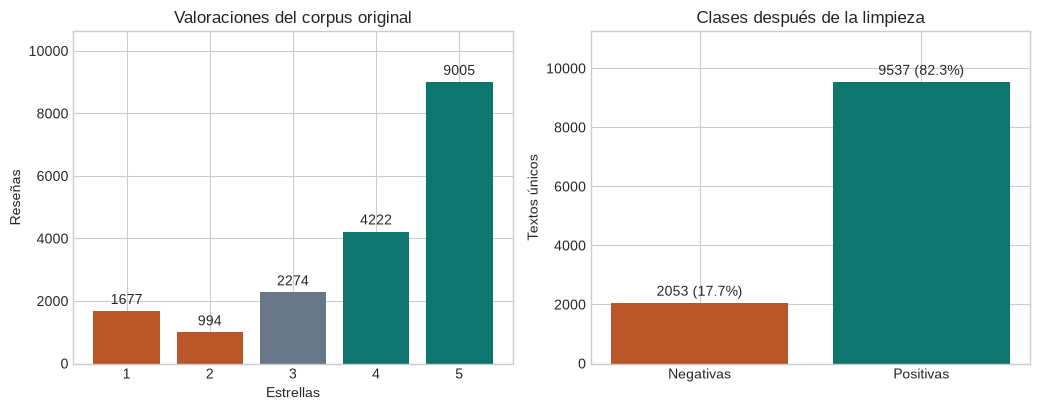

In [6]:
from collections import Counter

estrellas = Counter(int(fila["rating"]) for fila in originales)
clases = Counter(int(fila["label"]) for fila in resenas)
fig, ejes = plt.subplots(1, 2, figsize=(10.5, 4.2))
barras = ejes[0].bar(range(1, 6), [estrellas[i] for i in range(1, 6)],
                    color=[NARANJA, NARANJA, GRIS, TURQUESA, TURQUESA])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(title="Valoraciones del corpus original", xlabel="Estrellas", ylabel="Reseñas", ylim=(0, max(estrellas.values()) * 1.18))
ejes[0].set_xticks(range(1, 6))
barras = ejes[1].bar(["Negativas", "Positivas"], [clases[0], clases[1]], color=[NARANJA, TURQUESA])
ejes[1].bar_label(barras, [f"{clases[i]} ({clases[i]/len(resenas):.1%})" for i in (0, 1)], padding=3)
ejes[1].set(title="Clases después de la limpieza", ylabel="Textos únicos", ylim=(0, max(clases.values()) * 1.18))
mostrar_figura(fig, "01_distribucion_del_corpus")

## 4. Crear las particiones por grupos

Se conectan reseñas del mismo hotel conocido y textos que coinciden al quitar espacios y puntuación. A partir de cinco pliegues estratificados por grupos, se fijan tres para **entrenamiento**, uno para **validación** y uno para **prueba** (aproximadamente 60/20/20). Estos conjuntos fijos cumplen funciones distintas. No se equilibran por submuestreo y se comprueba la separación de grupos, hoteles y coincidencias de texto. Los hoteles sin identificador solo se pueden agrupar por coincidencia de texto.

In [7]:
def preparar_particiones(filas, semilla=SEMILLA):
    padres = list(range(len(filas)))

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = padres[i]
        return i

    def unir(a, b):
        a, b = raiz(a), raiz(b)
        padres[max(a, b)] = min(a, b)

    hoteles, textos = {}, {}
    for i, fila in enumerate(filas):
        for hotel in json.loads(fila["hoteles_json"]):
            clave = normalizar(hotel)
            if clave in hoteles:
                unir(i, hoteles[clave])
            hoteles[clave] = i
        # Une también variaciones que solo cambian puntuación o espacios.
        # No se declara detección exhaustiva de paráfrasis o duplicados cercanos.
        texto = re.sub(r"[\W_]+", "", normalizar(fila["review_text"]))
        if texto in textos:
            unir(i, textos[texto])
        textos[texto] = i
    grupos = np.array([raiz(i) for i in range(len(filas))])
    y = np.array([int(fila["label"]) for fila in filas])
    asignaciones = np.empty(len(filas), dtype=int)
    divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla)
    for fold, (_, indices) in enumerate(divisor.split(np.zeros(len(y)), y, grupos)):
        asignaciones[indices] = fold
    nombres = {0: "prueba", 1: "validacion", 2: "entrenamiento", 3: "entrenamiento", 4: "entrenamiento"}
    registros = [{"id": f["id"], "grupo": str(grupos[i]), "particion": nombres[asignaciones[i]]}
                 for i, f in enumerate(filas)]
    for nombre in set(nombres.values()):
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        if set(y[indices]) != {0, 1}:
            raise ValueError(f"La partición {nombre} no contiene ambas clases")
    destinos = {raiz(i): set() for i in range(len(filas))}
    for i, r in enumerate(registros):
        destinos[raiz(i)].add(r["particion"])
    assert all(len(v) == 1 for v in destinos.values())
    resumen = {
        "semilla": semilla,
        "metodo": "StratifiedGroupKFold de 5 folds; fold 0 prueba, 1 validación, 2–4 entrenamiento",
        "sha256_dataset": huella_csv(filas),
        "sha256_particiones": huella_csv(registros),
        "grupos": len(set(grupos.tolist())),
        "grupo_mayor": max(Counter(grupos.tolist()).values()),
        "regla_grupos": "Componentes conexas por hotel y por texto sin puntuación ni espacios; sin hotel queda agrupado solo por coincidencias de texto",
        "limitacion": "Los hoteles ausentes no permiten garantizar separación por establecimiento; no se detectan todas las paráfrasis",
        "balance": "No se submuestrea ni duplica ninguna partición; usar pesos calculados solo con entrenamiento",
        "particiones": {},
    }
    for nombre in ["entrenamiento", "validacion", "prueba"]:
        indices = [i for i, r in enumerate(registros) if r["particion"] == nombre]
        resumen["particiones"][nombre] = {
            "total": len(indices), "negativas": int(sum(y[indices] == 0)),
            "positivas": int(sum(y[indices] == 1)),
        }
    return registros, resumen


def verificar_particiones(filas, partes, resumen):
    por_id = {r["id"]: r["particion"] for r in partes}
    assert len(por_id) == len(partes) == len(filas)
    assert set(por_id) == {r["id"] for r in filas}
    assert set(por_id.values()) == {"entrenamiento", "validacion", "prueba"}
    hoteles, textos, grupos = defaultdict(set), defaultdict(set), defaultdict(set)
    for r in filas:
        nombre = por_id[r["id"]]
        for hotel in json.loads(r["hoteles_json"]):
            hoteles[normalizar(hotel)].add(nombre)
        textos[re.sub(r"[\W_]+", "", normalizar(r["review_text"]))].add(nombre)
    for r in partes:
        grupos[r["grupo"]].add(r["particion"])
    for categoria in [hoteles, textos, grupos]:
        assert all(len(particiones) == 1 for particiones in categoria.values())
    for nombre, conteo in resumen["particiones"].items():
        seleccion = [r for r in filas if por_id[r["id"]] == nombre]
        assert len(seleccion) == conteo["total"]
        assert sum(r["label"] == "0" for r in seleccion) == conteo["negativas"]
        assert sum(r["label"] == "1" for r in seleccion) == conteo["positivas"]


def separar_conjuntos(filas, asignaciones, resumen):
    por_id = {fila["id"]: fila for fila in asignaciones}
    conjuntos = {nombre: [] for nombre in resumen["particiones"]}
    for fila in filas:
        conjuntos[por_id[fila["id"]]["particion"]].append(fila)
    return conjuntos, {identificador: fila["grupo"] for identificador, fila in por_id.items()}


asignaciones, particiones = preparar_particiones(resenas)
verificar_particiones(resenas, asignaciones, particiones)
escribir_json(DATOS / "particiones.json", particiones)
conjuntos, grupos_por_id = separar_conjuntos(resenas, asignaciones, particiones)
display(pd.DataFrame(particiones["particiones"]).T)

,total,negativas,positivas
entrenamiento,6949,1229,5720
validacion,2324,414,1910
prueba,2317,410,1907


## 5. Entrenar candidatos y elegir en validación

TF-IDF usa unigramas y bigramas de palabras, conserva las tildes y no elimina palabras vacías para retener negaciones como «no». El vectorizador se ajusta dentro del pipeline, solo con el conjunto de entrenamiento. Se comparan:

- una **referencia mayoritaria**;
- **regresión logística** con y sin pesos balanceados;
- **Complement Naive Bayes**, variante de Naive Bayes para texto desbalanceado;
- **SVM lineal** con y sin pesos balanceados;
- **KNN** con distancia coseno, adecuada para vectores TF-IDF;
- **árbol de decisión** con pesos balanceados.

La elección maximiza F1 macro en validación; en caso de empate se prioriza el recall de negativas. F1 macro da el mismo peso a cada clase, relevante ante el desbalance del corpus.

In [8]:
def crear_clasificador(nombre):
    clasificadores = {
        "logistica": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000,
                                        solver="liblinear", random_state=SEMILLA),
        "naive_bayes": ComplementNB(alpha=1.0),
        "svm": LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEMILLA),
        "knn": KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance"),
        "arbol": DecisionTreeClassifier(max_depth=30, class_weight="balanced", random_state=SEMILLA),
        "mayoritario": DummyClassifier(strategy="most_frequent"),
    }
    if nombre not in clasificadores:
        raise ValueError(f"Modelo desconocido: {nombre}")
    return clasificadores[nombre]


def construir_modelo(nombre="logistica", umbral=None, **parametros):
    """Pipeline TF-IDF + clasificador para textos de review_text.

    `umbral` fija el corte sobre la puntuación de la clase negativa (0): la reseña
    se marca como negativa cuando su puntuación es mayor o igual que el umbral.
    Sin umbral se usa la regla de decisión propia del clasificador.
    """
    modelo = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.98,
                                  max_features=40000, sublinear_tf=True,
                                  stop_words=None, strip_accents=None)),
        ("clasificador", crear_clasificador(nombre)),
    ])
    modelo.set_params(**parametros)
    if umbral is not None:
        modelo.set_params(clasificador=FixedThresholdClassifier(
            modelo.named_steps["clasificador"], threshold=float(umbral), pos_label=0,
        ))
    return modelo


def textos_y_etiquetas(filas):
    return [fila["review_text"] for fila in filas], [int(fila["label"]) for fila in filas]


def puntuacion_negativa(modelo, textos):
    """Puntuación creciente con la evidencia de reseña negativa (clase 0)."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(textos)[:, 0]
    return -modelo.decision_function(textos)


def metricas(etiquetas, predicciones):
    reporte = classification_report(
        etiquetas, predicciones, labels=[0, 1], target_names=["negativa", "positiva"],
        output_dict=True, zero_division=0,
    )
    return {
        "f1_macro": reporte["macro avg"]["f1-score"],
        "exactitud": reporte["accuracy"],
        "negativa": reporte["negativa"],
        "positiva": reporte["positiva"],
        "matriz_confusion": confusion_matrix(etiquetas, predicciones, labels=[0, 1]).tolist(),
    }


def evaluar(modelo, filas):
    textos, etiquetas = textos_y_etiquetas(filas)
    predicciones = modelo.predict(textos)
    return metricas(etiquetas, predicciones), predicciones


def comparar(entrenamiento, validacion, rejilla):
    """Ajusta cada candidato con entrenamiento y elige por F1 macro en validación."""
    textos, etiquetas = textos_y_etiquetas(entrenamiento)
    resultados = []
    mejor_modelo = None
    mejor_resultado = None
    mejor_puntuacion = (-1, -1)
    for nombre, opciones in {"mayoritario": {}, **rejilla}.items():
        for parametros in ParameterGrid(opciones):
            modelo = construir_modelo(nombre, **parametros).fit(textos, etiquetas)
            resultado_metricas, _ = evaluar(modelo, validacion)
            resultado = {"modelo": nombre, "parametros": parametros, "metricas": resultado_metricas}
            resultados.append(resultado)
            puntuacion = resultado_metricas["f1_macro"], resultado_metricas["negativa"]["recall"]
            if puntuacion > mejor_puntuacion:
                mejor_puntuacion = puntuacion
                mejor_resultado = resultado
                mejor_modelo = modelo
    return resultados, mejor_resultado, mejor_modelo


def describir_modelo(modelo):
    """Resumen legible del pipeline: algoritmo, parámetros principales y umbral."""
    clasificador = modelo.named_steps["clasificador"]
    umbral = None
    if isinstance(clasificador, FixedThresholdClassifier):
        umbral = clasificador.threshold
        clasificador = clasificador.estimator
    nombre = {
        LinearSVC: "svm", ComplementNB: "naive_bayes", LogisticRegression: "logistica",
        KNeighborsClassifier: "knn", DecisionTreeClassifier: "arbol", DummyClassifier: "mayoritario",
    }.get(type(clasificador), type(clasificador).__name__)
    claves = {
        "svm": ["C", "class_weight"], "naive_bayes": ["alpha"], "logistica": ["C", "class_weight"],
        "knn": ["n_neighbors", "weights"], "arbol": ["max_depth", "class_weight"], "mayoritario": [],
    }.get(nombre, [])
    parametros = {clave: clasificador.get_params()[clave] for clave in claves}
    tfidf = modelo.named_steps["tfidf"]
    return {
        "algoritmo": nombre,
        "nombre": ALGORITMOS.get(nombre, nombre),
        "parametros": parametros,
        "tfidf": {"ngram_range": list(tfidf.ngram_range), "min_df": tfidf.min_df,
                  "max_features": tfidf.max_features},
        "umbral": umbral,
    }


tfidf = {"tfidf__ngram_range": [(1, NGRAMAS_MAX)], "tfidf__min_df": [MIN_DF],
         "tfidf__max_features": [MAX_TERMINOS]}
rejilla_completa = {
    "logistica": {"clasificador__C": C_LOGISTICA, "clasificador__class_weight": PESOS_LOGISTICA},
    "naive_bayes": {"clasificador__alpha": ALPHA_NAIVE_BAYES},
    "svm": {"clasificador__C": C_SVM, "clasificador__class_weight": PESOS_SVM},
    "knn": {"clasificador__n_neighbors": K_VECINOS},
    "arbol": {"clasificador__max_depth": PROFUNDIDAD_ARBOL, "clasificador__class_weight": PESOS_ARBOL},
}
rejilla = {familia: {**rejilla_completa[familia], **tfidf} for familia in FAMILIAS}
resultados, elegido, modelo_base = comparar(conjuntos["entrenamiento"], conjuntos["validacion"], rejilla)


def describir_parametros(parametros):
    return ", ".join(f'{clave.removeprefix("clasificador__")}={valor}' for clave, valor in parametros.items()
                     if clave.startswith("clasificador__")) or "—"


tabla_candidatos = pd.DataFrame([{
    "Modelo": ALGORITMOS[r["modelo"]], "Parámetros": describir_parametros(r["parametros"]),
    "F1 macro": r["metricas"]["f1_macro"], "Exactitud": r["metricas"]["exactitud"],
    "Recall negativas": r["metricas"]["negativa"]["recall"],
    "Precisión negativas": r["metricas"]["negativa"]["precision"],
} for r in resultados]).sort_values("F1 macro", ascending=False)
display(tabla_candidatos.style.format({c: "{:.4f}" for c in tabla_candidatos.columns[2:]}).hide(axis="index"))
print(f'Elegido en validación: {ALGORITMOS[elegido["modelo"]]} · {describir_parametros(elegido["parametros"])}')

Modelo,Parámetros,F1 macro,Exactitud,Recall negativas,Precisión negativas
SVM lineal,"C=2.0, class_weight=balanced",0.9381,0.9643,0.8816,0.9148
SVM lineal,"C=2.0, class_weight=None",0.9336,0.9626,0.8478,0.9360
SVM lineal,"C=1.0, class_weight=balanced",0.9332,0.9608,0.8913,0.8892
SVM lineal,"C=0.5, class_weight=balanced",0.9330,0.9604,0.9010,0.8797
SVM lineal,"C=1.0, class_weight=None",0.9312,0.9613,0.8430,0.9332
SVM lineal,"C=0.5, class_weight=None",0.9298,0.9608,0.8309,0.9425
Complement Naive Bayes,alpha=0.5,0.9290,0.9604,0.8285,0.9423
Regresión logística,"C=2.0, class_weight=balanced",0.9152,0.9484,0.9058,0.8224
Regresión logística,"C=1.0, class_weight=balanced",0.9138,0.9466,0.9251,0.8046
Regresión logística,"C=2.0, class_weight=None",0.9111,0.9522,0.7633,0.9605


Elegido en validación: SVM lineal · C=2.0, class_weight=balanced


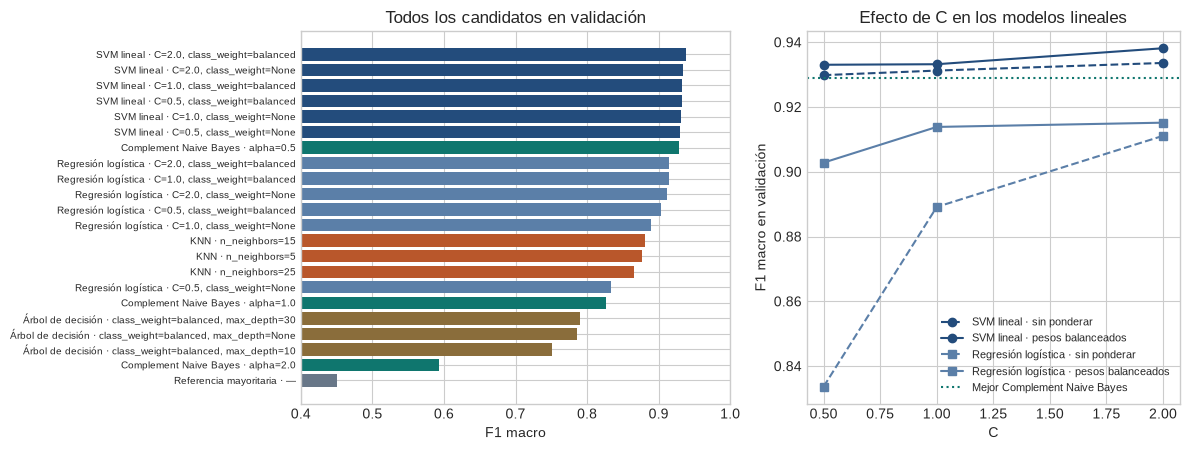

In [9]:
mejores_familia = {}
for r in resultados:
    if r["modelo"] not in mejores_familia or r["metricas"]["f1_macro"] > mejores_familia[r["modelo"]]["metricas"]["f1_macro"]:
        mejores_familia[r["modelo"]] = r

lineales = [f for f in ("svm", "logistica") if f in FAMILIAS]
fig, ejes = plt.subplots(1, 2 if lineales else 1, figsize=(12 if lineales else 7, 4.6), squeeze=False,
                         gridspec_kw={"width_ratios": [1.15, 1]} if lineales else None)
ejes = ejes[0]
orden = sorted(resultados, key=lambda r: r["metricas"]["f1_macro"])
etiquetas = [f'{ALGORITMOS[r["modelo"]].split(" (")[0]} · {describir_parametros(r["parametros"])}' for r in orden]
ejes[0].barh(etiquetas, [r["metricas"]["f1_macro"] for r in orden], color=[COLORES_FAMILIA[r["modelo"]] for r in orden])
ejes[0].set(title="Todos los candidatos en validación", xlabel="F1 macro", xlim=(0.4, 1.0))
ejes[0].tick_params(axis="y", labelsize=7)
if lineales:
    estilos = {"svm": (AZUL, "o", "SVM lineal"), "logistica": ("#5b7fa8", "s", "Regresión logística")}
    for familia in lineales:
        color, marcador, nombre = estilos[familia]
        for peso, linea in [(None, "--"), ("balanced", "-")]:
            serie = sorted((r["parametros"]["clasificador__C"], r["metricas"]["f1_macro"]) for r in resultados
                           if r["modelo"] == familia and r["parametros"]["clasificador__class_weight"] == peso)
            if serie:
                ejes[1].plot(*zip(*serie), marker=marcador, linestyle=linea, color=color,
                             label=f'{nombre} · {"pesos balanceados" if peso else "sin ponderar"}')
    if "naive_bayes" in mejores_familia:
        ejes[1].axhline(mejores_familia["naive_bayes"]["metricas"]["f1_macro"], color=TURQUESA, linestyle=":",
                        label="Mejor Complement Naive Bayes")
    ejes[1].set(title="Efecto de C en los modelos lineales", xlabel="C", ylabel="F1 macro en validación")
    ejes[1].legend(loc="lower right", fontsize=8)
mostrar_figura(fig, "02_parametros_en_validacion")

## 6. Ajustar el umbral de decisión en validación

Para el administrador, una queja que pasa como positiva cuesta más que revisar una falsa alarma. Por eso se fija una **meta de recall de negativas** (`META_RECALL_NEGATIVAS`) y se ajusta el umbral del modelo elegido **solo con validación**: entre los cortes que alcanzan la meta, se toma el de mayor F1 macro (`ajustar_umbral`). Como salvaguarda, solo se aceptan cortes que no pierdan más de 0,02 de F1 macro frente a la regla predeterminada; si ninguno lo cumple, se conserva esa regla. La puntuación es la evidencia de reseña negativa: para la SVM, el opuesto de la distancia firmada al hiperplano; para modelos probabilísticos, la probabilidad de la clase negativa. El umbral queda guardado dentro del pipeline mediante `FixedThresholdClassifier`, de modo que la API aplica la misma regla.

,Regla predeterminada,Modelo final
F1 macro,0.9381,0.9365
Recall negativas,0.8816,0.9034
Precisión negativas,0.9148,0.8884


Umbral elegido: -0.0711 (meta de recall 90%)


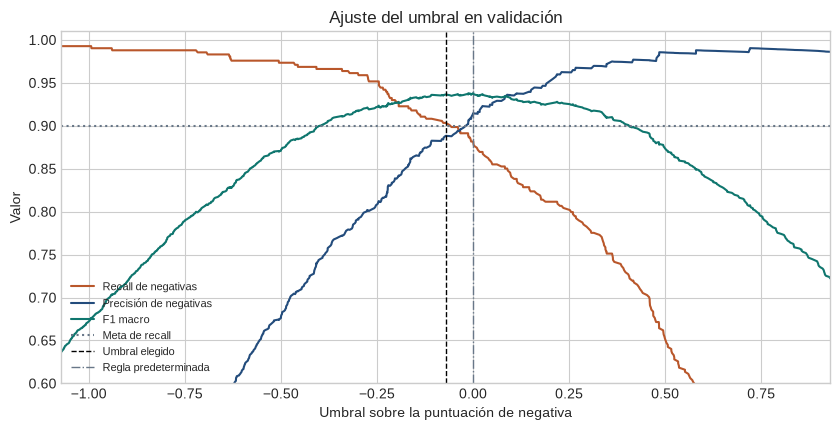

In [10]:
TOLERANCIA_F1 = 0.02


def ajustar_umbral(modelo, validacion, meta_recall_negativas, tolerancia_f1=TOLERANCIA_F1):
    """Elige el umbral en validación según la prioridad de no perder quejas.

    Entre los cortes que alcanzan la meta de recall de negativas sin perder más de
    `tolerancia_f1` de F1 macro frente a la regla predeterminada, se queda con el de
    mayor F1 macro; en empate, con el de mayor precisión de negativas. Si ningún corte
    cumple ambas condiciones devuelve `None` y se conserva la regla predeterminada.
    Devuelve también la curva de cortes evaluados. No consulta la prueba reservada.
    """
    if not (hasattr(modelo, "predict_proba") or hasattr(modelo, "decision_function")):
        raise ValueError("El clasificador no ofrece puntuaciones para ajustar el umbral.")
    textos, etiquetas = textos_y_etiquetas(validacion)
    etiquetas = np.asarray(etiquetas)
    puntuaciones = puntuacion_negativa(modelo, textos)
    negativas = etiquetas == 0
    def f1(verdaderos, predichos, reales):
        return 0.0 if predichos + reales == 0 else 2 * verdaderos / (predichos + reales)

    curva = []
    for corte in np.unique(puntuaciones):
        predichas_negativas = puntuaciones >= corte
        vn = int(np.sum(predichas_negativas & negativas))  # negativas detectadas
        vp = int(np.sum(~predichas_negativas & ~negativas))  # positivas correctas
        recall = vn / max(1, int(negativas.sum()))
        precision = vn / max(1, int(predichas_negativas.sum()))
        f1_macro = (f1(vn, int(predichas_negativas.sum()), int(negativas.sum()))
                    + f1(vp, int((~predichas_negativas).sum()), int((~negativas).sum()))) / 2
        curva.append({"umbral": float(corte), "recall_negativas": recall,
                      "precision_negativas": precision, "f1_macro": f1_macro})
    f1_predeterminado = metricas(etiquetas, modelo.predict(textos))["f1_macro"]
    aptos = [punto for punto in curva if punto["recall_negativas"] >= meta_recall_negativas
             and punto["f1_macro"] >= f1_predeterminado - tolerancia_f1]
    if not aptos:
        return None, curva
    elegido = max(aptos, key=lambda p: (p["f1_macro"], p["precision_negativas"], p["umbral"]))
    return elegido, curva


if META_RECALL_NEGATIVAS is None or elegido["modelo"] == "mayoritario":
    umbral, curva_umbral = None, []
else:
    umbral, curva_umbral = ajustar_umbral(modelo_base, conjuntos["validacion"], META_RECALL_NEGATIVAS)
valor_umbral = None if umbral is None else umbral["umbral"]
textos_entrenamiento, etiquetas_entrenamiento = textos_y_etiquetas(conjuntos["entrenamiento"])
modelo_elegido = construir_modelo(elegido["modelo"], umbral=valor_umbral, **elegido["parametros"]).fit(
    textos_entrenamiento, etiquetas_entrenamiento)
metricas_validacion_umbral, _ = evaluar(modelo_elegido, conjuntos["validacion"])
display(pd.DataFrame({
    "Regla predeterminada": {"F1 macro": elegido["metricas"]["f1_macro"],
                             "Recall negativas": elegido["metricas"]["negativa"]["recall"],
                             "Precisión negativas": elegido["metricas"]["negativa"]["precision"]},
    "Modelo final": {"F1 macro": metricas_validacion_umbral["f1_macro"],
                     "Recall negativas": metricas_validacion_umbral["negativa"]["recall"],
                     "Precisión negativas": metricas_validacion_umbral["negativa"]["precision"]},
}).style.format("{:.4f}"))
print("Se conserva la regla predeterminada." if umbral is None else
      f'Umbral elegido: {valor_umbral:.4f} (meta de recall {META_RECALL_NEGATIVAS:.0%})')

if curva_umbral:
    curva = pd.DataFrame(curva_umbral)
    regla = 0.5 if hasattr(modelo_base, "predict_proba") else 0
    centro = regla if valor_umbral is None else valor_umbral
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    ax.plot(curva["umbral"], curva["recall_negativas"], color=NARANJA, label="Recall de negativas")
    ax.plot(curva["umbral"], curva["precision_negativas"], color=AZUL, label="Precisión de negativas")
    ax.plot(curva["umbral"], curva["f1_macro"], color=TURQUESA, label="F1 macro")
    ax.axhline(META_RECALL_NEGATIVAS, color=GRIS, linestyle=":", label="Meta de recall")
    ax.axvline(centro, color="black", linestyle="--", linewidth=1, label="Umbral elegido")
    ax.axvline(regla, color=GRIS, linestyle="-.", linewidth=1, label="Regla predeterminada")
    ax.set(title="Ajuste del umbral en validación", xlabel="Umbral sobre la puntuación de negativa",
           ylabel="Valor", ylim=(0.6, 1.01), xlim=(centro - 1.0, centro + 1.0))
    ax.legend(loc="lower left", fontsize=8)
    mostrar_figura(fig, "03_umbral_en_validacion")

## 7. Evaluar en la prueba reservada

Se mide solo el modelo final: el candidato elegido con su umbral. Las filas de la matriz representan la etiqueta real y las columnas la predicción. Como referencia se informa también el mismo pipeline con la regla predeterminada; esta cifra no interviene en ninguna elección. Revisamos especialmente las reseñas negativas clasificadas como positivas porque son posibles quejas que el administrador no encontraría con el filtro.

,precision,recall,f1-score,support
Negativa,0.877647,0.909756,0.893413,410.0
Positiva,0.980444,0.972732,0.976573,1907.0


F1 macro: 0.9350 · Exactitud: 96.2%
Sin ajuste de umbral (referencia): F1 macro 0.9386 · recall de negativas 90.0%


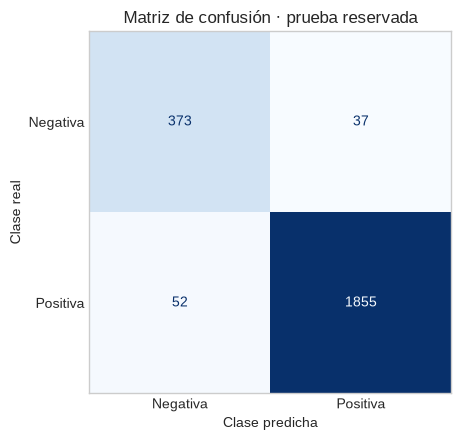

In [11]:
if EVALUAR_PRUEBA:
    prueba = conjuntos["prueba"]
    metricas_prueba, predicciones = evaluar(modelo_elegido, prueba)
    metricas_prueba_sin_umbral, _ = evaluar(modelo_base, prueba)
    display(pd.DataFrame({"Negativa": metricas_prueba["negativa"], "Positiva": metricas_prueba["positiva"]}).T)
    print(f'F1 macro: {metricas_prueba["f1_macro"]:.4f} · Exactitud: {metricas_prueba["exactitud"]:.1%}')
    print(f'Sin ajuste de umbral (referencia): F1 macro {metricas_prueba_sin_umbral["f1_macro"]:.4f} · '
          f'recall de negativas {metricas_prueba_sin_umbral["negativa"]["recall"]:.1%}')
    fig, ax = plt.subplots(figsize=(6, 4.5))
    matriz = np.asarray(metricas_prueba["matriz_confusion"])
    ConfusionMatrixDisplay(matriz, display_labels=["Negativa", "Positiva"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.grid(False)
    ax.set(title="Matriz de confusión · prueba reservada", xlabel="Clase predicha", ylabel="Clase real")
    mostrar_figura(fig, "04_matriz_de_confusion")

## 8. Validación cruzada dentro de entrenamiento

Se rotan cinco pliegues por grupos **solo dentro de entrenamiento** (función `validacion_cruzada`). En cada rotación se vuelve a ajustar TF-IDF y se evalúa el modelo final junto al mejor candidato de cada familia sobre el mismo pliegue. Sirve para comprobar que la elección no depende de una única partición de validación; la selección de la aplicación corresponde al protocolo de las secciones 5 a 7.

Configuración,F1 macro,Exactitud,Recall negativas
Modelo de la aplicación (con umbral),0.9378 ± 0.0071,0.9636,0.9040
"Regresión logística · C=2.0, class_weight=balanced",0.9272 ± 0.0085,0.9561,0.9211
Complement Naive Bayes · alpha=0.5,0.9063 ± 0.0158,0.9504,0.7511
"SVM lineal · C=2.0, class_weight=balanced",0.9382 ± 0.0095,0.9645,0.8829
KNN (distancia coseno) · n_neighbors=15,0.8672 ± 0.0107,0.9327,0.6535
"Árbol de decisión · class_weight=balanced, max_depth=30",0.7688 ± 0.0102,0.8577,0.6721


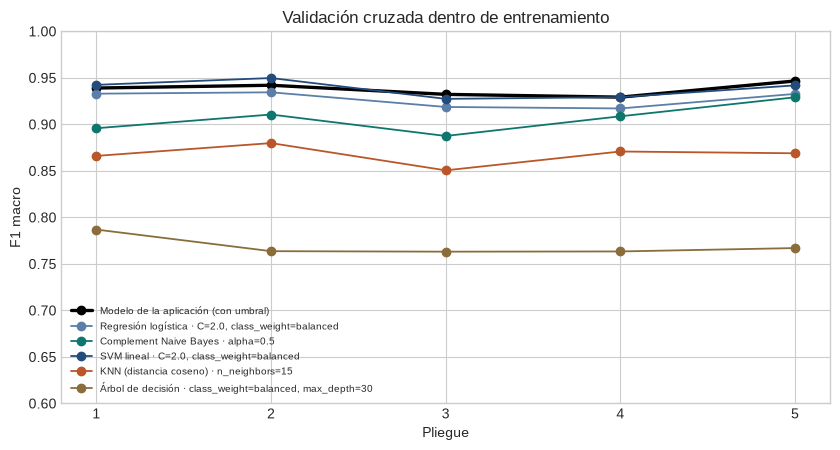

In [12]:
def validacion_cruzada(configuraciones, filas, grupos_por_id, pliegues=5):
    """Rota pliegues por grupos dentro de `filas` y reajusta cada pipeline por pliegue."""
    from sklearn.base import clone

    textos, etiquetas = textos_y_etiquetas(filas)
    grupos = [grupos_por_id[fila["id"]] for fila in filas]
    resultados = {nombre: [] for nombre in configuraciones}
    divisor = StratifiedGroupKFold(n_splits=pliegues, shuffle=True, random_state=SEMILLA)
    for numero, (ajuste, evaluacion) in enumerate(divisor.split(textos, etiquetas, grupos), start=1):
        if {grupos[i] for i in ajuste} & {grupos[i] for i in evaluacion}:
            raise RuntimeError(f"Se repiten grupos entre ajuste y evaluación en el pliegue {numero}")
        for nombre, pipeline in configuraciones.items():
            modelo = clone(pipeline).fit([textos[i] for i in ajuste], [etiquetas[i] for i in ajuste])
            resultado, _ = evaluar(modelo, [filas[i] for i in evaluacion])
            resultados[nombre].append({
                "pliegue": numero,
                "n_ajuste": len(ajuste),
                "n_evaluacion": len(evaluacion),
                "f1_macro": resultado["f1_macro"],
                "exactitud": resultado["exactitud"],
                "recall_negativas": resultado["negativa"]["recall"],
            })
    return resultados


if VALIDACION_CRUZADA:
    configuraciones = {"modelo_de_la_aplicacion": construir_modelo(
        elegido["modelo"], umbral=valor_umbral, **elegido["parametros"])}
    for familia, resultado in mejores_familia.items():
        if familia != "mayoritario":
            configuraciones[familia] = construir_modelo(familia, **resultado["parametros"])
    pliegues = validacion_cruzada(configuraciones, conjuntos["entrenamiento"], grupos_por_id)
    resumen_cv = {
        nombre: {campo: {"media": mean(p[campo] for p in filas),
                         "desviacion_estandar_muestral": stdev(p[campo] for p in filas)}
                 for campo in ("f1_macro", "exactitud", "recall_negativas")}
        for nombre, filas in pliegues.items()
    }
    nombres_cv = {"modelo_de_la_aplicacion": "Modelo de la aplicación (con umbral)",
                  **{familia: f"{ALGORITMOS[familia]} · {describir_parametros(mejores_familia[familia]['parametros'])}"
                     for familia in configuraciones if familia != "modelo_de_la_aplicacion"}}
    display(pd.DataFrame([{
        "Configuración": nombres_cv[nombre],
        "F1 macro": f'{r["f1_macro"]["media"]:.4f} ± {r["f1_macro"]["desviacion_estandar_muestral"]:.4f}',
        "Exactitud": f'{r["exactitud"]["media"]:.4f}',
        "Recall negativas": f'{r["recall_negativas"]["media"]:.4f}',
    } for nombre, r in resumen_cv.items()]).style.hide(axis="index"))
    escribir_json(RESULTADOS / "revision_materia.json", {
        "alcance": "Validación cruzada posterior a la selección, solo sobre entrenamiento",
        "scikit_learn": version("scikit-learn"),
        "n_entrenamiento": len(conjuntos["entrenamiento"]),
        "sha256_particiones": particiones["sha256_particiones"],
        "metodo": "StratifiedGroupKFold, 5 pliegues y semilla 42. Pipeline ajustado por pliegue.",
        "configuraciones": {nombre: describir_modelo(modelo) for nombre, modelo in configuraciones.items()},
        "resultados_por_pliegue": pliegues,
        "resumen": resumen_cv,
    })

    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for nombre in configuraciones:
        color = "black" if nombre == "modelo_de_la_aplicacion" else COLORES_FAMILIA[nombre]
        ax.plot([p["pliegue"] for p in pliegues[nombre]], [p["f1_macro"] for p in pliegues[nombre]],
                marker="o", color=color, linewidth=2.4 if nombre == "modelo_de_la_aplicacion" else 1.3,
                label=nombres_cv[nombre])
    ax.set(title="Validación cruzada dentro de entrenamiento", xlabel="Pliegue", ylabel="F1 macro", ylim=(0.6, 1.0))
    ax.set_xticks(range(1, 6))
    ax.legend(loc="lower left", fontsize=7.5)
    mostrar_figura(fig, "05_validacion_cruzada")

## 9. Exportar el modelo y comprobar su recarga

El archivo `sentimiento.joblib` reúne TF-IDF, el clasificador ajustado y su umbral. El backend lo consume junto a `metricas.json`, que registra su huella y el protocolo. La exportación conserva las etiquetas internas y verifica que el pipeline recargado produzca las mismas predicciones. `errores_prueba.json` registra identificadores y clases para revisar errores sin copiar el texto de los comentarios. Con los parámetros incluidos se obtiene el **modelo de referencia evaluado** en `resultados/modelo/`. Las ejecuciones lanzadas desde la herramienta de entrenamiento escriben en su propia carpeta (`CARPETA_SALIDA`), sin prueba reservada; la aplicación puede activar una de ellas y siempre puede volver al modelo de referencia.

In [13]:
if EXPORTAR_MODELO:
    DESTINO_MODELO.mkdir(parents=True, exist_ok=True)
    validacion = conjuntos["validacion"]
    referencia = prueba if EVALUAR_PRUEBA else validacion
    with tempfile.TemporaryDirectory(dir=DESTINO_MODELO.parent, prefix=".modelo-") as directorio:
        temporal = Path(directorio)
        pipeline = temporal / "sentimiento.joblib"
        joblib.dump(modelo_elegido, pipeline, compress=3)
        recargado = joblib.load(pipeline)
        textos_referencia = [fila["review_text"] for fila in referencia]
        np.testing.assert_array_equal(recargado.predict(textos_referencia), modelo_elegido.predict(textos_referencia))
        archivos = ["sentimiento.joblib", "metricas.json"]
        if EVALUAR_PRUEBA:
            escribir_json(temporal / "errores_prueba.json", [
                {"id": fila["id"], "etiqueta": int(fila["label"]), "prediccion": int(prediccion)}
                for fila, prediccion in zip(prueba, predicciones, strict=True)
                if int(fila["label"]) != prediccion
            ])
            archivos.append("errores_prueba.json")
        escribir_json(temporal / "metricas.json", {
            "origen": "cuaderno",
            "carpeta_salida": CARPETA_SALIDA,
            "parametros_ejecucion": {
                "familias": FAMILIAS, "ngramas_max": NGRAMAS_MAX, "min_df": MIN_DF, "max_terminos": MAX_TERMINOS,
                "meta_recall_negativas": META_RECALL_NEGATIVAS, "validacion_cruzada": VALIDACION_CRUZADA,
                "evaluar_prueba": EVALUAR_PRUEBA,
            },
            "versiones": {paquete: version(paquete) for paquete in ["scikit-learn", "numpy", "joblib"]},
            "semilla_particiones": particiones["semilla"],
            "sha256_dataset": particiones["sha256_dataset"],
            "sha256_particiones": particiones["sha256_particiones"],
            "seleccion": "F1 macro de validación, luego recall negativo, luego orden de evaluación",
            "ajuste_pipeline": "Solo entrenamiento",
            "labels_matriz": {"0": "negativa", "1": "positiva"},
            "ejes_matriz": "Filas reales, columnas predichas, orden 0 y 1",
            "comparacion_validacion": resultados,
            "elegido_validacion": elegido,
            "umbral": {"meta_recall_negativas": META_RECALL_NEGATIVAS, "tolerancia_f1": TOLERANCIA_F1,
                       **(umbral or {"umbral": None}),
                       "regla": "Mayor F1 macro de validación entre los cortes que alcanzan la meta"},
            "modelo": describir_modelo(modelo_elegido),
            "evaluacion_validacion": metricas_validacion_umbral,
            "evaluacion_validacion_sin_umbral": elegido["metricas"],
            "validacion_cruzada": resumen_cv.get("modelo_de_la_aplicacion") if VALIDACION_CRUZADA else None,
            "evaluacion_prueba": metricas_prueba if EVALUAR_PRUEBA else None,
            "evaluacion_prueba_sin_umbral": metricas_prueba_sin_umbral if EVALUAR_PRUEBA else None,
            "pipeline": {"archivo": pipeline.name, "sha256": sha256(pipeline)},
        })
        for nombre in archivos:
            (temporal / nombre).replace(DESTINO_MODELO / nombre)
    print(f"Pipeline recargado y verificado. Exportación: {DESTINO_MODELO.relative_to(BASE)}")

Pipeline recargado y verificado. Exportación: resultados/modelo


## 10. Explorar grupos de quejas para apoyar decisiones

Después de la clasificación binaria, la aplicación agrupa las reseñas negativas del archivo cargado mediante **TF-IDF y K-means**. Se ajusta una representación independiente para ese archivo; el clasificador de sentimiento y sus métricas se conservan. Esta sección utiliza la misma función del backend para reproducir su comportamiento.

Como exploración se agrupan las reseñas con etiqueta negativa de **entrenamiento**, sin consultar la prueba reservada. La interfaz trabaja con las negativas **predichas**, que pueden contener errores de clasificación. Se eliminan palabras funcionales españolas únicamente para descubrir temas. Se consideran palabras de al menos tres letras y hasta 5.000 términos. La semilla es 42 y se realizan diez inicializaciones.

### 10.1 ¿Cuántos grupos? Método del codo y coeficiente de silueta

Antes de fijar la cantidad de grupos se aplica el **método del codo** visto en clase: se entrena K-means con distintos valores de *k* y se grafica la inercia (suma de distancias al centroide). Se complementa con el **coeficiente de silueta**, que mide si cada reseña está más cerca de su grupo que del grupo vecino (de −1 a 1). Se repite sobre una reducción LSA de 30 componentes (`TruncatedSVD`), habitual para agrupar texto, para comprobar si la conclusión depende de la alta dimensión de TF-IDF.

inercia            silueta        
representacion    LSA 30     TF-IDF  LSA 30  TF-IDF
k                                                  
2               919.6344  1195.9977  0.0396  0.0062
3               886.6496  1192.5860  0.0449  0.0052
4               861.7277  1190.0144  0.0479  0.0050
5               840.7038  1188.1752  0.0524  0.0041
6               821.6127  1186.9210  0.0529  0.0038
7               805.1228  1185.0796  0.0555  0.0038
8               792.9815  1183.8525  0.0559  0.0032
9               779.6937  1184.4394  0.0568  0.0021
10              768.9028  1181.9350  0.0587  0.0025

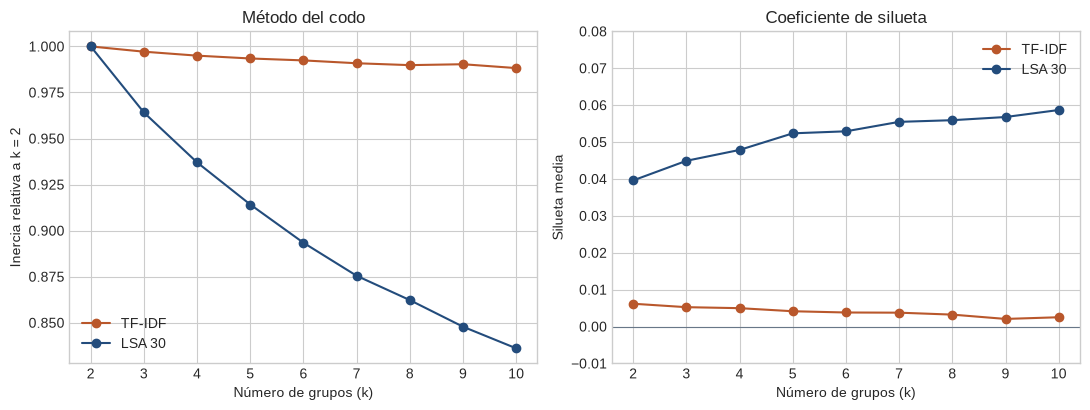

In [14]:
if EXPLORAR_GRUPOS:
    from backend import PALABRAS_FUNCIONALES

    negativas_exploracion = [fila for fila in conjuntos["entrenamiento"] if fila["label"] == "0"]
    vectorizador_temas = TfidfVectorizer(stop_words=PALABRAS_FUNCIONALES, token_pattern=r"(?u)\b[^\W\d_]{3,}\b",
                                         max_features=5_000, sublinear_tf=True)
    matriz_temas = vectorizador_temas.fit_transform(fila["review_text"] for fila in negativas_exploracion)
    lsa = make_pipeline(TruncatedSVD(30, random_state=SEMILLA), Normalizer(copy=False))
    matriz_lsa = lsa.fit_transform(matriz_temas)

    VALORES_K = list(range(2, 11))
    codo = []
    for representacion, matriz, metrica in [("TF-IDF", matriz_temas, "cosine"), ("LSA 30", matriz_lsa, "euclidean")]:
        for k in VALORES_K:
            agrupador = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(matriz)
            codo.append({"representacion": representacion, "k": k, "inercia": agrupador.inertia_,
                         "silueta": silhouette_score(matriz, agrupador.labels_, metric=metrica, random_state=SEMILLA)})
    codo = pd.DataFrame(codo)
    display(codo.pivot(index="k", columns="representacion", values=["inercia", "silueta"]).round(4))

    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
    for representacion, color in [("TF-IDF", NARANJA), ("LSA 30", AZUL)]:
        datos = codo[codo["representacion"] == representacion]
        relativa = datos["inercia"] / datos["inercia"].iloc[0]
        ejes[0].plot(datos["k"], relativa, marker="o", color=color, label=representacion)
        ejes[1].plot(datos["k"], datos["silueta"], marker="o", color=color, label=representacion)
    ejes[0].set(title="Método del codo", xlabel="Número de grupos (k)", ylabel="Inercia relativa a k = 2")
    ejes[1].set(title="Coeficiente de silueta", xlabel="Número de grupos (k)", ylabel="Silueta media", ylim=(-0.01, 0.08))
    ejes[1].axhline(0, color=GRIS, linewidth=0.8)
    for eje in ejes:
        eje.set_xticks(VALORES_K)
        eje.legend()
    mostrar_figura(fig, "06_codo_y_silueta")
    escribir_json(RESULTADOS / "codo_silueta.json", {
        "origen": "etiquetas negativas del conjunto de entrenamiento",
        "n": len(negativas_exploracion),
        "resultados": codo.to_dict(orient="records"),
    })

**Lectura.** Si los comentarios formaran grupos bien separados, la inercia caería bruscamente hasta cierto *k* y después se aplanaría, y la silueta tendría un máximo claro. No ocurre en ninguna de las dos representaciones. Con TF-IDF la inercia apenas baja (alrededor de 1 % entre *k* = 2 y 10) y la silueta es casi nula y decreciente (0,006 a 0,002). Con LSA la inercia desciende de forma casi lineal, sin codo, y la silueta crece muy despacio (0,040 a 0,059) sin un máximo en el rango. Las quejas comparten vocabulario y se solapan, por lo que el codo no señala un *k* óptimo. Como se vio en clase, en ese caso la cantidad puede fijarse por **criterio de experto**: la aplicación usa como máximo **cinco grupos**, una cantidad que un administrador puede revisar, y la reduce en archivos pequeños (raíz de la mitad de las reseñas utilizables, redondeada hacia arriba). Los grupos se presentan como ayuda exploratoria, no como categorías validadas.

### 10.2 Grupos obtenidos con la función del backend

Cada fila pertenece a un grupo; los textos sin términos utilizables se conservan en un grupo aparte. Los tres términos de mayor peso medio identifican cada grupo. **Los nombres describen vocabulario compartido, no categorías operativas validadas ni causas demostradas.** Un comentario puede hablar de varios asuntos y el volumen no mide gravedad. Referencia técnica: [agrupación de documentos con K-means, scikit-learn](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html).

,Grupo,Palabras representativas,Reseñas
0,1,habitación · noche · recepción,332
1,2,habitaciones · estrellas · mal,305
2,3,baño · habitación · cama,257
3,4,servicio · comida · hora,217
4,5,reserva · booking · día,118


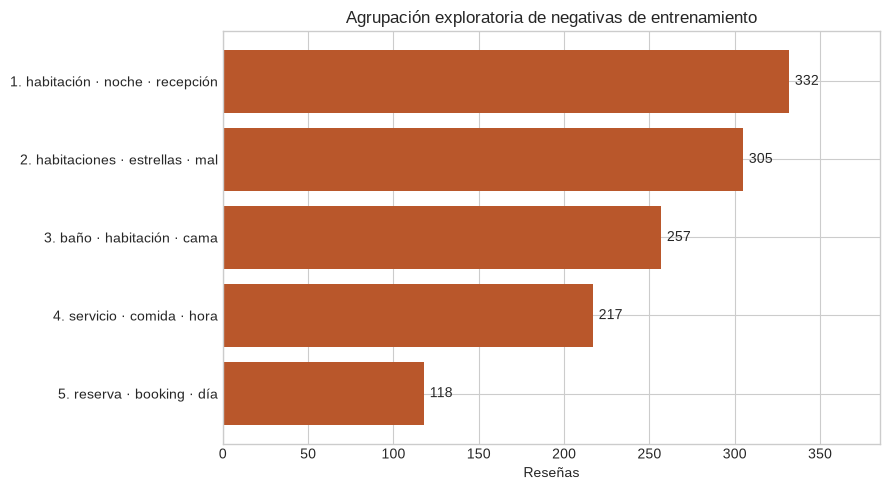

In [15]:
if EXPLORAR_GRUPOS:
    from backend import LoteNegativas, agrupar_negativas

    agrupacion = agrupar_negativas(LoteNegativas(resenas=[
        {"numero": i, "texto": fila["review_text"]}
        for i, fila in enumerate(negativas_exploracion, 1)
    ]))
    assert sum(grupo.cantidad for grupo in agrupacion.grupos) == len(negativas_exploracion)
    assert sorted(numero for grupo in agrupacion.grupos for numero in grupo.resenas) == list(
        range(1, len(negativas_exploracion) + 1)
    )
    resumen_temas = pd.DataFrame([
        {"Grupo": grupo.id, "Palabras representativas": grupo.tema, "Reseñas": grupo.cantidad}
        for grupo in agrupacion.grupos
    ])
    display(resumen_temas)
    fig, eje = plt.subplots(figsize=(9, 5))
    barras = eje.barh(
        [f"{grupo.id}. {grupo.tema}" for grupo in agrupacion.grupos],
        [grupo.cantidad for grupo in agrupacion.grupos], color=NARANJA,
    )
    eje.bar_label(barras, padding=4)
    eje.invert_yaxis()
    eje.set(title="Agrupación exploratoria de negativas de entrenamiento", xlabel="Reseñas")
    eje.set_xlim(0, max(grupo.cantidad for grupo in agrupacion.grupos) * 1.16)
    mostrar_figura(fig, "07_grupos_de_quejas")
    escribir_json(RESULTADOS / "agrupacion_exploratoria.json", {
        "origen": "etiquetas negativas del conjunto de entrenamiento",
        "total": agrupacion.total,
        "grupos": [{**grupo.model_dump(), "ids_corpus": [
            negativas_exploracion[numero - 1]["id"] for numero in grupo.resenas
        ]} for grupo in agrupacion.grupos],
    })

## Lectura de resultados

Al ampliar la comparación con los modelos vistos en clase, la **SVM lineal con C = 2 y pesos balanceados** obtuvo el mayor F1 macro en validación (0,9381), por delante de Complement Naive Bayes con alpha = 0,5 (0,9290), la regresión logística (0,9152), KNN (0,8804) y el árbol de decisión (0,7896). La validación cruzada dentro de entrenamiento confirma el orden de las familias: SVM 0,938 ± 0,010, regresión logística 0,927, Naive Bayes 0,906, KNN 0,867 y árbol 0,769.

El umbral ajustado en validación para alcanzar al menos 90 % de recall de negativas quedó en −0,071 sobre la puntuación de negativa. En la **prueba reservada**, el modelo final obtuvo F1 macro de **0,9350**, exactitud de 96,2 % y detectó **373 de 410 reseñas negativas** (recall de 91,0 %), con 52 positivas marcadas como negativas. Como referencia, la misma SVM con la regla predeterminada habría obtenido F1 macro de 0,9386 y 369 negativas detectadas: en prueba, el umbral recuperó cuatro quejas más a cambio de diez falsas alarmas adicionales. La elección se mantiene porque se hizo con validación y responde a la prioridad del administrador; la prueba no se usa para reajustarla.

La agrupación organiza vocabulario compartido entre las negativas y conserva su trazabilidad. El método del codo y la silueta muestran que esas quejas no forman grupos naturales bien separados, por lo que el número de grupos responde a un criterio de uso y no a un óptimo estadístico.

El desempeño mide la concordancia con etiquetas derivadas de estrellas en AHR. Las valoraciones mixtas y los cambios de idioma o región limitan la interpretación de la evidencia. Las clasificaciones y los grupos apoyan la revisión humana de los comentarios.